# ThreatLens — Task 4: Data Collection, EDA & Preprocessing

**Dataset:** CICIDS2017 cleaned Parquet version (8 files)  
**Project:** ThreatLens — Intelligent Cybersecurity Decision Support System

This notebook:
1. Loads all 8 Parquet files from the uploaded ZIP.
2. Combines them into one dataset.
3. Examines structure, data types and statistics.
4. Checks missing/infinite values and duplicates.
5. Detects outliers using IQR.
6. Visualizes class distributions, feature distributions and correlations.
7. Cleans invalid values and duplicates.
8. Creates a cleaned CSV for the next project phases.
9. Demonstrates scaling without data leakage using a train/test split.


## 1. Why this dataset is suitable for ThreatLens

The uploaded archive contains the eight CICIDS2017 Parquet files:

- Benign-Monday-no-metadata.parquet
- Botnet-Friday-no-metadata.parquet
- Bruteforce-Tuesday-no-metadata.parquet
- DDoS-Friday-no-metadata.parquet
- DoS-Wednesday-no-metadata.parquet
- Infiltration-Thursday-no-metadata.parquet
- Portscan-Friday-no-metadata.parquet
- WebAttacks-Thursday-no-metadata.parquet

The dataset contains 78 columns: 77 network-flow features and the `Label` target. The labels include benign traffic and multiple attack types, making it appropriate for intrusion/threat detection.


In [ ]:
# 2. Install/read dependencies in Google Colab
# Colab normally has pandas, numpy, matplotlib and seaborn.
# PyArrow is required to read Parquet files.

!pip -q install pyarrow scikit-learn

import os
import zipfile
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully.")


Libraries imported successfully.


In [ ]:
# 3. Upload the dataset ZIP
from google.colab import files

uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))
print("Uploaded:", zip_name)


KeyboardInterrupt: 

### Re-upload the dataset and verify its size

It appears the previous upload might have been corrupted or incomplete, leading to a `BadZipFile` error. Please re-upload the `CICIDS2017_Cleaned_Parquet.zip` file. After uploading, we will verify its size to ensure the upload was successful before attempting to extract its contents.

In [ ]:
from google.colab import files
import os

uploaded = files.upload()

zip_name = next(iter(uploaded.keys()))
print("Re-uploaded file:", zip_name)

# Verify the file size
file_size_bytes = os.path.getsize(zip_name)
file_size_mb = file_size_bytes / (1024 * 1024)
print(f"File size: {file_size_mb:.2f} MB")

print("Please check that the file size is as expected for the ZIP archive (e.g., around 1 GB).")


Saving archive (1).zip to archive (1).zip
Re-uploaded file: archive (1).zip
File size: 226.90 MB
Please check that the file size is as expected for the ZIP archive (e.g., around 1 GB).


Now that the file is re-uploaded, you can re-run the extraction cell below (cell 28375391) to attempt extracting the contents again.

In [ ]:
# 4. Extract the ZIP
DATA_DIR = "/content/ThreatLens_CICIDS2017"

os.makedirs(DATA_DIR, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(DATA_DIR)

parquet_files = sorted(glob.glob(os.path.join(DATA_DIR, "*.parquet")))

print("Parquet files found:", len(parquet_files))
for f in parquet_files:
    print(os.path.basename(f))


Parquet files found: 8
Benign-Monday-no-metadata.parquet
Botnet-Friday-no-metadata.parquet
Bruteforce-Tuesday-no-metadata.parquet
DDoS-Friday-no-metadata.parquet
DoS-Wednesday-no-metadata.parquet
Infiltration-Thursday-no-metadata.parquet
Portscan-Friday-no-metadata.parquet
WebAttacks-Thursday-no-metadata.parquet


## 2. Load all files

Do not treat the files as unrelated datasets. They are class/day partitions of the same CICIDS2017 flow dataset, so they are combined for the ThreatLens analysis.


In [ ]:
# 5. Load each Parquet file and inspect its size
file_info = []

for path in parquet_files:
    temp = pd.read_parquet(path)
    file_info.append({
        "File": os.path.basename(path),
        "Rows": len(temp),
        "Columns": len(temp.columns),
        "Label_Values": temp["Label"].nunique() if "Label" in temp.columns else None
    })
    print(f"{os.path.basename(path):45s} -> {temp.shape}")

file_info_df = pd.DataFrame(file_info)
display(file_info_df)


Benign-Monday-no-metadata.parquet             -> (458831, 78)
Botnet-Friday-no-metadata.parquet             -> (176038, 78)
Bruteforce-Tuesday-no-metadata.parquet        -> (389714, 78)
DDoS-Friday-no-metadata.parquet               -> (221264, 78)
DoS-Wednesday-no-metadata.parquet             -> (584991, 78)
Infiltration-Thursday-no-metadata.parquet     -> (207630, 78)
Portscan-Friday-no-metadata.parquet           -> (119522, 78)
WebAttacks-Thursday-no-metadata.parquet       -> (155820, 78)


,File,Rows,Columns,Label_Values
0,Benign-Monday-no-metadata.parquet,458831,78,1
1,Botnet-Friday-no-metadata.parquet,176038,78,2
2,Bruteforce-Tuesday-no-metadata.parquet,389714,78,3
3,DDoS-Friday-no-metadata.parquet,221264,78,2
4,DoS-Wednesday-no-metadata.parquet,584991,78,6
5,Infiltration-Thursday-no-metadata.parquet,207630,78,2
6,Portscan-Friday-no-metadata.parquet,119522,78,2
7,WebAttacks-Thursday-no-metadata.parquet,155820,78,4


In [ ]:
# 6. Combine all eight files
dfs = [pd.read_parquet(path) for path in parquet_files]

df = pd.concat(dfs, ignore_index=True)

print("Combined shape:", df.shape)
display(df.head())


Combined shape: (2313810, 78)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,4,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,3.000000e+06,5.000000e+05,4.000000,0.000000,4,4,4,4.0,0.000000,4,4,0,0.000000,0.000000,0,0,0,0,0,0,40,0,5.000000e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
1,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2,6,3,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,4.000000e+06,6.666667e+05,3.000000,0.000000,3,3,3,3.0,0.000000,3,3,0,0.000000,0.000000,0,0,0,0,0,0,40,0,6.666667e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
3,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
4,6,609,7,4,484,414,233,0,69.14286,111.967896,207,0,103.5,119.511505,1.474548e+06,1.806240e+04,60.900002,115.194954,381,2,609,101.5,177.089523,460,2,467,155.666672,263.560883,460,3,0,0,0,0,164,104,1.149425e+04,6568.144531,0,233,74.833336,107.527443,11562.151367,0,0,0,1,0,0,0,0,0,81.63636,69.14286,103.5,0,0,0,0,0,0,7,484,4,414,8192,2053,5,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


In [ ]:
# 7. Dataset structure
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.value_counts())

print("\nDataset info:")
df.info()


Rows: 2313810
Columns: 78

Column names:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE F

,count
int32,26
float32,22
int8,19
int16,7
float64,2
int64,1
object,1



Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2313810 entries, 0 to 2313809
Data columns (total 78 columns):
 #   Column                    Dtype  
---  ------                    -----  
 0   Protocol                  int8   
 1   Flow Duration             int32  
 2   Total Fwd Packets         int32  
 3   Total Backward Packets    int32  
 4   Fwd Packets Length Total  int32  
 5   Bwd Packets Length Total  int32  
 6   Fwd Packet Length Max     int16  
 7   Fwd Packet Length Min     int16  
 8   Fwd Packet Length Mean    float32
 9   Fwd Packet Length Std     float32
 10  Bwd Packet Length Max     int16  
 11  Bwd Packet Length Min     int16  
 12  Bwd Packet Length Mean    float32
 13  Bwd Packet Length Std     float32
 14  Flow Bytes/s              float64
 15  Flow Packets/s            float64
 16  Flow IAT Mean             float32
 17  Flow IAT Std              float32
 18  Flow IAT Max              int32  
 19  Flow IAT Min              int32  
 20  Fwd IAT T

### Expected dataset size

For this exact archive, the combined dataset should contain approximately **2,313,810 rows and 78 columns** before duplicate removal.

The dataset contains **77 numerical flow features + `Label`**. The features include destination port, flow duration, packet counts, packet lengths, inter-arrival times, TCP flag counts, window sizes, active/idle statistics and related flow measures.


In [ ]:
# 8. Numerical and categorical feature identification
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Number of numerical columns:", len(numeric_cols))
print("Number of categorical columns:", len(categorical_cols))

print("\nCategorical columns:")
print(categorical_cols)

print("\nFirst 20 numerical columns:")
print(numeric_cols[:20])


Number of numerical columns: 77
Number of categorical columns: 1

Categorical columns:
['Label']

First 20 numerical columns:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min']


In [ ]:
# 9. Summary statistics
display(df.describe())

print("\nDetailed statistics:")
display(df[numeric_cols].describe().T)


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2313810.0,2.313810e+06,2313810.0,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2313810.0,2313810.0,2313810.0,2313810.0,2313810.0,2313810.0,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2.313810e+06,2313810.0,2.313810e+06,2.313810e+06,2.313810e+06
mean,1.050673e+01,1.807575e+07,1.108391e+01,1.255334e+01,6.664045e+02,1.976976e+04,2.506291e+02,2.142396e+01,6.880502e+01,8.299153e+01,1.063222e+03,4.806050e+01,3.721294e+02,4.102253e+02,4.968873e+05,2.043416e+04,1.575399e+06,3.571411e+06,1.122074e+07,1.855538e+05,1.770549e+07,3.180206e+06,3.996830e+06,1.105010e+07,1.237065e+06,1.210414e+07,2.209131e+06,1.817957e+06,5.731222e+06,1.183272e+06,3.834196e-02,0.0,9.940315e-06,0.0,-3.181561e+04,-2.784879e+03,1.606678e+04,4.439551e+03,1.884181e+01,1.158088e+03,2.072441e+02,3.589645e+02,5.940462e+05,3.273562e-02,3.834196e-02,2.964807e-04,2.717704e-01,2.873780e-01,9.027578e-02,9.940315e-06,2.977773e-04,7.052675e-01,2.305290e+02,6.880502e+01,3.721294e+02,0.0,0.0,0.0,0.0,0.0,0.0,1.108391e+01,6.663916e+02,1.255334e+01,1.976934e+04,7.250858e+03,2.133285e+03,6.537630e+00,-3.360480e+03,9.977085e+04,5.032398e+04,1.874053e+05,7.131980e+04,10172613.0,6.164088e+05,1.063716e+07,9.688133e+06
std,5.416040e+00,3.640823e+07,8.291879e+02,1.103179e+03,1.105009e+04,2.503141e+06,7.855073e+02,6.334192e+01,2.017213e+02,3.041364e+02,2.105197e+03,7.315087e+01,6.500732e+02,9.072180e+02,8.071022e+06,1.242807e+05,4.896976e+06,8.844810e+06,2.661597e+07,3.144030e+06,3.635325e+07,1.048758e+07,1.054554e+07,2.670714e+07,9.448828e+06,3.136118e+07,9.732726e+06,6.819687e+06,1.882250e+07,9.176014e+06,1.920205e-01,0.0,3.152812e-03,0.0,2.328613e+07,1.606258e+06,1.127672e+05,3.025491e+04,2.646334e+01,2.189594e+03,3.259423e+02,6.831851e+02,1.821079e+06,1.779438e-01,1.920205e-01,1.721607e-02,4.448723e-01,4.525395e-01,2.865765e-01,3.152812e-03,1.725366e-02,7.089600e-01,3.527746e+02,2.017213e+02,6.500732e+02,0.0,0.0,0.0,0.0,0.0,0.0,8.291879e+02,1.103514e+04,1.103179e+03,2.503107e+06,1.482118e+04,8.793197e+03,7.039324e+02,1.200084e+0


Detailed statistics:


,count,mean,std,min,25%,50%,75%,max
Protocol,2313810.0,1.050673e+01,5.416040e+00,0.000000e+00,6.000000,6.000000,1.700000e+01,1.700000e+01
Flow Duration,2313810.0,1.807575e+07,3.640823e+07,-1.300000e+01,476.000000,64783.000000,5.856948e+06,1.200000e+08
Total Fwd Packets,2313810.0,1.108391e+01,8.291879e+02,1.000000e+00,2.000000,2.000000,6.000000e+00,2.197590e+05
Total Backward Packets,2313810.0,1.255334e+01,1.103179e+03,0.000000e+00,1.000000,2.000000,5.000000e+00,2.919220e+05
Fwd Packets Length Total,2313810.0,6.664045e+02,1.105009e+04,0.000000e+00,37.000000,74.000000,3.560000e+02,1.290000e+07
Bwd Packets Length Total,2313810.0,1.976976e+04,2.503141e+06,0.000000e+00,26.000000,183.000000,2.306000e+03,6.554530e+08
Fwd Packet Length Max,2313810.0,2.506291e+02,7.855073e+02,0.000000e+00,20.000000,43.000000,2.740000e+02,2.482000e+04
Fwd Packet Length Min,2313810.0,2.142396e+01,6.334192e+01,0.000000e+00,0.000000,6.000000,3.900000e+01,2.325000e+03
Fwd Packet Length Mean,2313810.0,6.880502e+01,2.017213e+02,0.000000e+00,8.666667,39.555557,5.400000e+01,5.940857e+03
Fwd Packet Length Std,2313810.0,8.299153e+01,3.041364e+02,0.000000e+00,0.000000,0.000000,8.499406e+01,7.125597e+03


## 3. Missing-value and invalid-value analysis

Missing values and infinite values are checked before modeling. The cleaned Parquet version of this dataset is expected to have no missing records, but the notebook verifies this rather than assuming it.


In [ ]:
# 10. Missing values
missing = df.isnull().sum()
missing_table = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df)) * 100
}).sort_values("Missing_Count", ascending=False)

display(missing_table[missing_table["Missing_Count"] > 0])

print("TOTAL MISSING VALUES:", int(df.isnull().sum().sum()))


,Missing_Count,Missing_Percentage


TOTAL MISSING VALUES: 0


In [ ]:
# 11. Infinite values
inf_counts = pd.Series(
    np.isinf(df[numeric_cols]).sum(),
    index=numeric_cols
).sort_values(ascending=False)

display(inf_counts[inf_counts > 0])

print("TOTAL INFINITE VALUES:", int(inf_counts.sum()))


,0


TOTAL INFINITE VALUES: 0


In [ ]:
# 12. Handle invalid values safely
# Replace +/- infinity with NaN.
df = df.replace([np.inf, -np.inf], np.nan)

# Numeric missing values -> median
for col in numeric_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

# Categorical missing values -> mode
for col in categorical_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after treatment:", int(df.isnull().sum().sum()))


Missing values after treatment: 0


## 4. Duplicate analysis

Duplicate flow records can bias later modeling, so exact duplicate rows are identified and removed.


In [ ]:
# 13. Duplicate rows
duplicate_count = int(df.duplicated().sum())

print("Duplicate rows found:", duplicate_count)
print("Shape before duplicate removal:", df.shape)

df = df.drop_duplicates().reset_index(drop=True)

print("Shape after duplicate removal:", df.shape)
print("Remaining duplicates:", int(df.duplicated().sum()))


Duplicate rows found: 82004
Shape before duplicate removal: (2313810, 78)
Shape after duplicate removal: (2231806, 78)
Remaining duplicates: 0


### Expected duplicate result

For this exact CICIDS2017 archive, the combined data contains **82,004 duplicate rows** and the cleaned dataset contains **2,231,806 rows and 78 columns** after duplicate removal.


In [ ]:
# 14. Final validation after basic cleaning
print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Infinite values:", int(np.isinf(df[numeric_cols]).sum().sum()))


Shape: (2231806, 78)
Missing values: 0
Duplicate rows: 0
Infinite values: 0


## 5. Target/attack analysis

`Label` is the target variable. We retain the original multi-class label because ThreatLens is intended to explain different threat categories, not only benign-vs-attack traffic.


In [ ]:
# 15. Multi-class attack distribution
label_counts = df["Label"].value_counts()

print("Number of classes:", df["Label"].nunique())
display(label_counts.to_frame("Count"))

label_percent = (label_counts / len(df) * 100).round(4)
display(label_percent.to_frame("Percentage"))


Number of classes: 15


,Count
Label,
Benign,1895314
DoS Hulk,172846
DDoS,128014
DoS GoldenEye,10286
FTP-Patator,5931
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3219
PortScan,1956


,Percentage
Label,
Benign,84.9229
DoS Hulk,7.7447
DDoS,5.7359
DoS GoldenEye,0.4609
FTP-Patator,0.2657
DoS slowloris,0.2413
DoS Slowhttptest,0.2342
SSH-Patator,0.1442
PortScan,0.0876


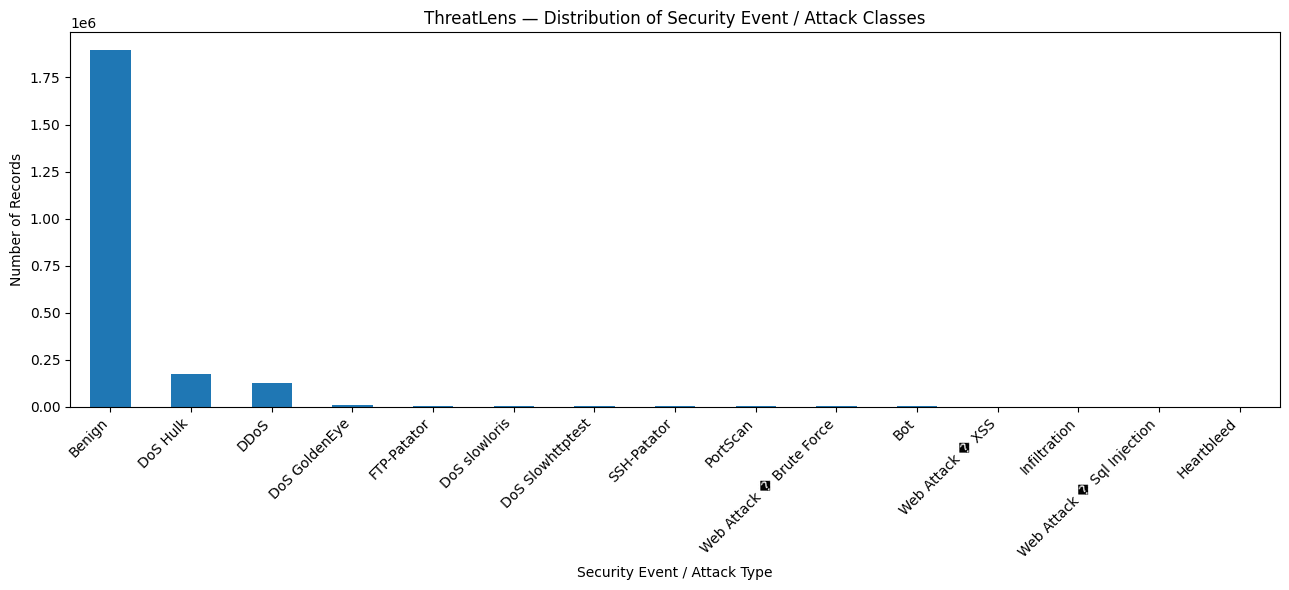

In [ ]:
# 16. Attack distribution bar chart
plt.figure(figsize=(13, 6))
label_counts.sort_values(ascending=False).plot(kind="bar")
plt.title("ThreatLens — Distribution of Security Event / Attack Classes")
plt.xlabel("Security Event / Attack Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Known class distribution for this cleaned version

The expected cleaned counts are:

| Label | Count |
|---|---:|
| Benign | 1,895,314 |
| DoS Hulk | 172,846 |
| DDoS | 128,014 |
| DoS GoldenEye | 10,286 |
| FTP-Patator | 5,931 |
| DoS slowloris | 5,385 |
| DoS Slowhttptest | 5,228 |
| SSH-Patator | 3,219 |
| PortScan | 1,956 |
| Web Attack Brute Force | 1,470 |
| Bot | 1,437 |
| Web Attack XSS | 652 |
| Infiltration | 36 |
| Web Attack Sql Injection | 21 |
| Heartbleed | 11 |

This shows a strong class imbalance, with benign traffic dominating the dataset.


## 6. Binary threat view

For some later models, ThreatLens may use:
- `0` = Benign
- `1` = Attack

But the original multi-class `Label` should be preserved for explanation and multi-class classification.


,Count
Threat_Binary,
Benign,1895314
Attack,336492


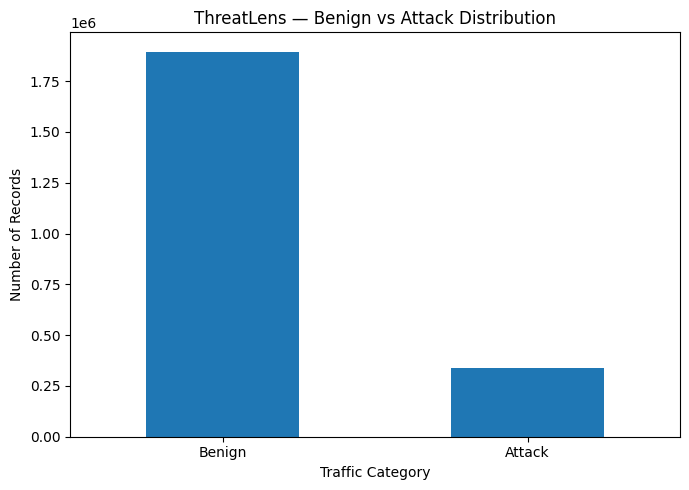

In [ ]:
# 17. Create a binary threat label without deleting the original Label
df["Threat_Binary"] = np.where(
    df["Label"].str.strip().str.lower().eq("benign"),
    0,
    1
)

binary_counts = df["Threat_Binary"].map({
    0: "Benign",
    1: "Attack"
}).value_counts()

display(binary_counts.to_frame("Count"))

plt.figure(figsize=(7, 5))
binary_counts.plot(kind="bar")
plt.title("ThreatLens — Benign vs Attack Distribution")
plt.xlabel("Traffic Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. Outlier detection using IQR

Cybersecurity traffic naturally contains extreme values. A large flow or packet count may be a real attack signal. Therefore, Task 4 **detects** outliers but does not blindly delete them.

The IQR method is used on selected high-value numeric features.


In [ ]:
# 18. Select representative features for outlier analysis
candidate_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean",
    "Packet Length Variance"
]

outlier_features = [c for c in candidate_features if c in df.columns]

print("Features selected for outlier analysis:")
print(outlier_features)


Features selected for outlier analysis:
['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Flow Bytes/s', 'Flow Packets/s', 'Packet Length Mean', 'Packet Length Variance']


In [ ]:
# 19. IQR outlier table
outlier_results = []

for col in outlier_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = int(((df[col] < lower) | (df[col] > upper)).sum())

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": count,
        "Outlier_Percentage": round(count / len(df) * 100, 4)
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table)


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Flow Duration,2037.000000,6.055697e+06,6.053660e+06,-9.078453e+06,1.513619e+07,462957,20.7436
1,Total Fwd Packets,2.000000,7.000000e+00,5.000000e+00,-5.500000e+00,1.450000e+01,216137,9.6844
2,Total Backward Packets,1.000000,6.000000e+00,5.000000e+00,-6.500000e+00,1.350000e+01,209898,9.4048
3,Flow Bytes/s,119.113669,2.057613e+04,2.045702e+04,-3.056641e+04,5.126166e+04,486314,21.7902
4,Flow Packets/s,1.244312,1.669867e+03,1.668623e+03,-2.501690e+03,4.172802e+03,520823,23.3364
5,Packet Length Mean,32.428570,2.066117e+02,1.741832e+02,-2.288462e+02,4.678865e+02,345962,15.5014
6,Packet Length Variance,76.800003,1.906194e+05,1.905426e+05,-2.857372e+05,4.764334e+05,371301,16.6368


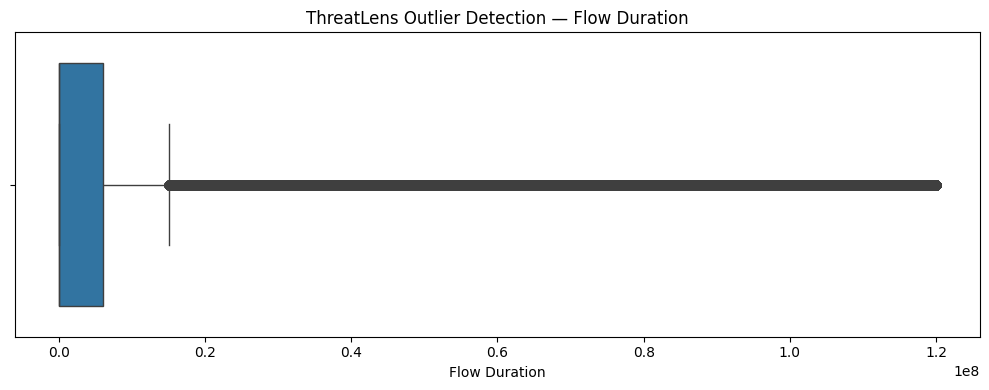

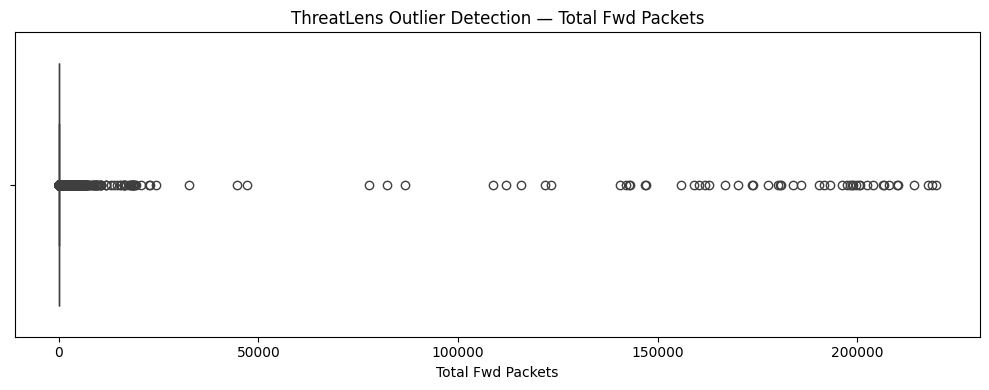

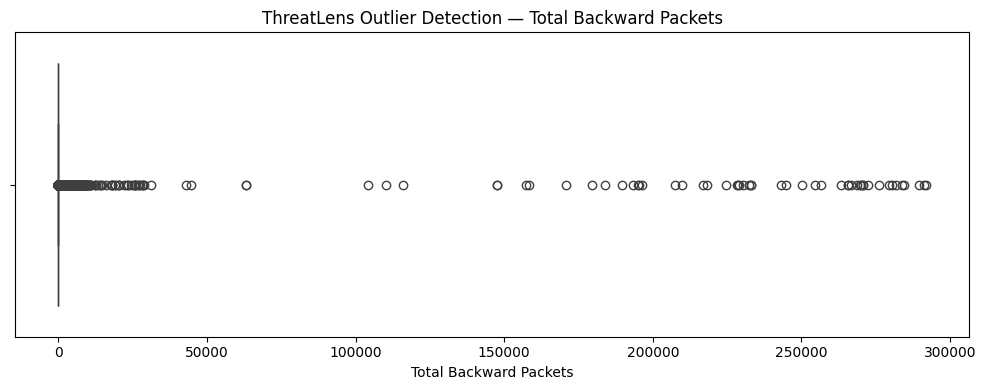

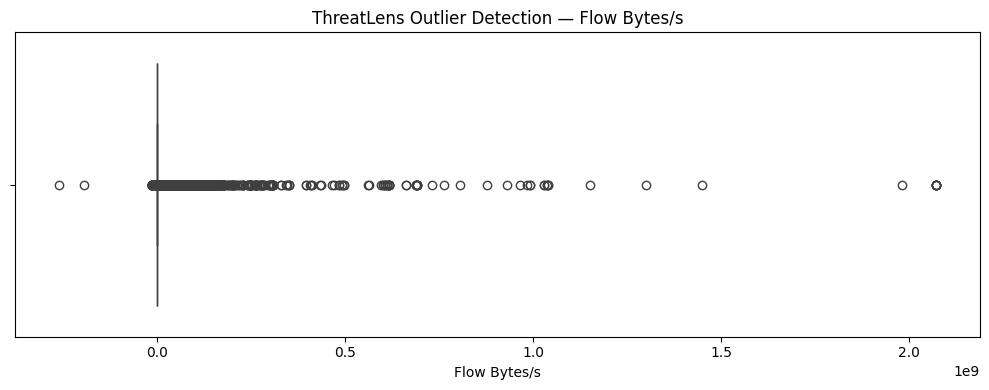

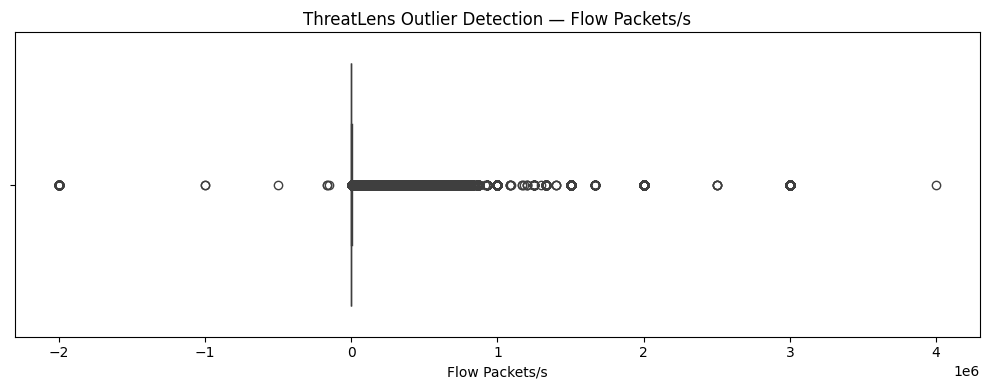

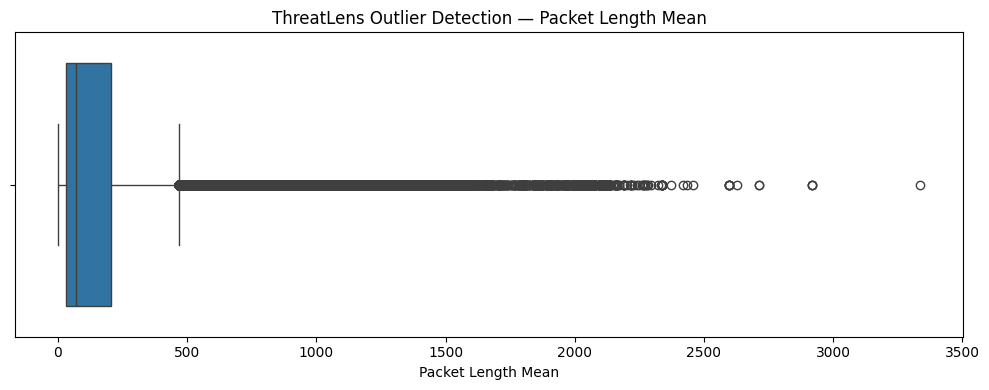

In [ ]:
# 20. Boxplots for representative features
for col in outlier_features[:6]:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f"ThreatLens Outlier Detection — {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


### Outlier treatment decision

Do **not** remove every IQR outlier in this dataset. Extreme traffic values can correspond to genuine DoS/DDoS or other malicious behavior. Only impossible/invalid values are corrected or removed. This preserves cybersecurity evidence for later detection models.


## 8. Feature distribution visualization

The full dataset has many features, so representative features are visualized instead of generating dozens of unreadable plots.


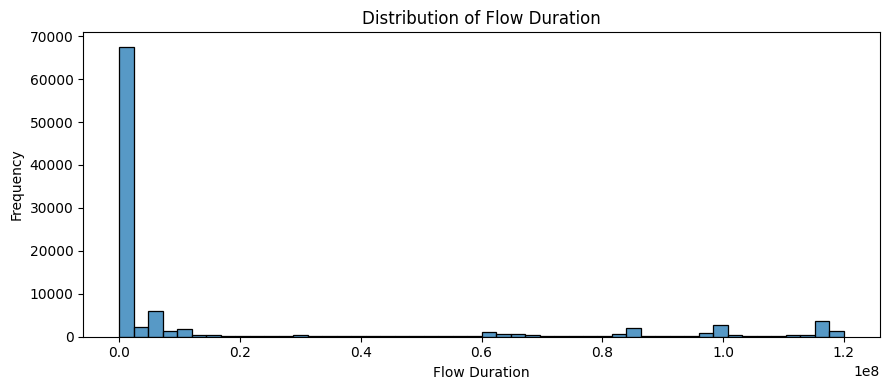

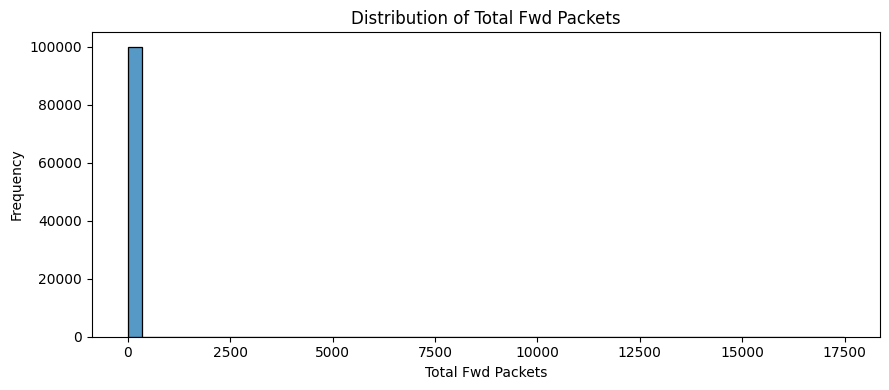

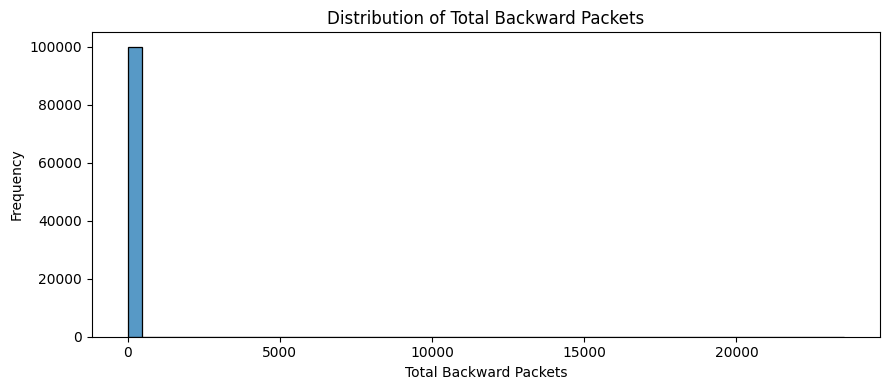

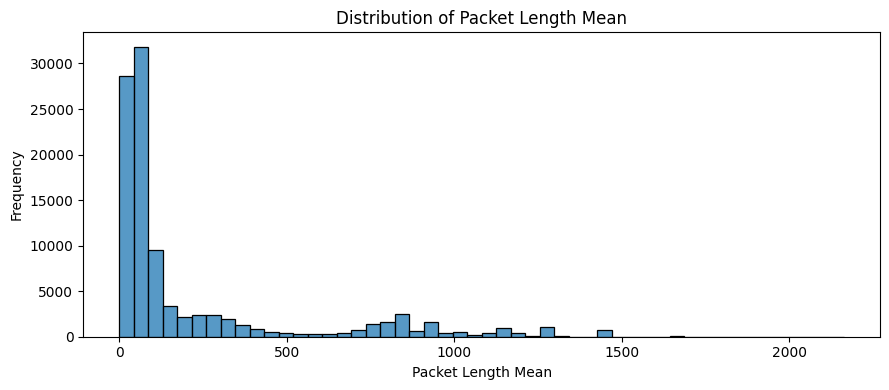

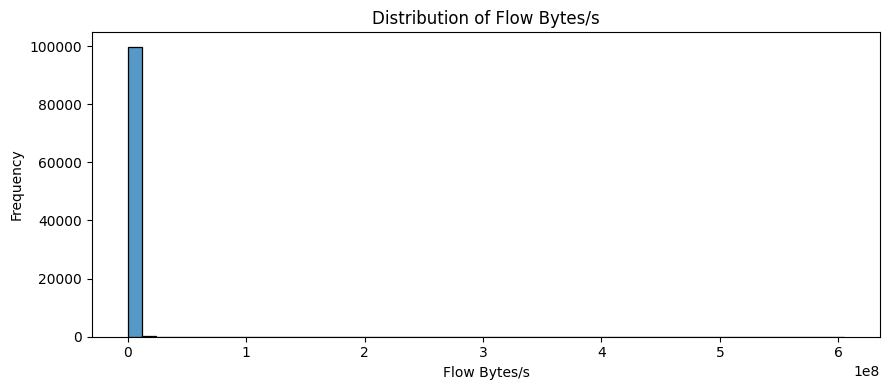

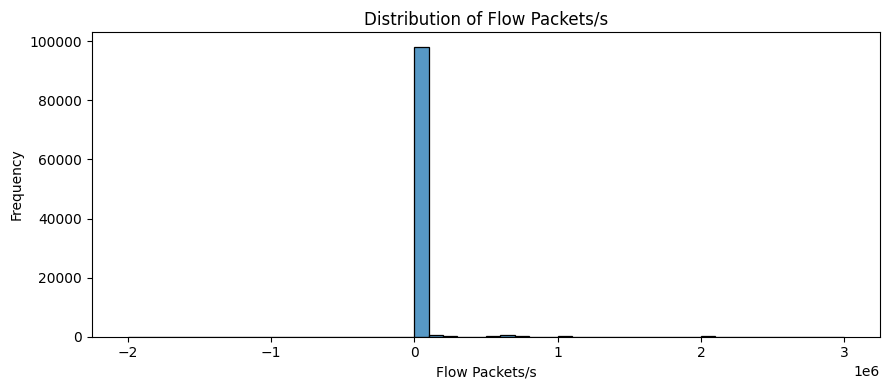

In [ ]:
# 21. Histograms of representative numeric features
hist_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Packet Length Mean",
    "Flow Bytes/s",
    "Flow Packets/s"
]
hist_features = [c for c in hist_features if c in df.columns]

# Sample for visualization to keep plots fast
plot_sample = df.sample(
    n=min(100000, len(df)),
    random_state=42
)

for col in hist_features:
    plt.figure(figsize=(9, 4))
    sns.histplot(plot_sample[col], bins=50, kde=False)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


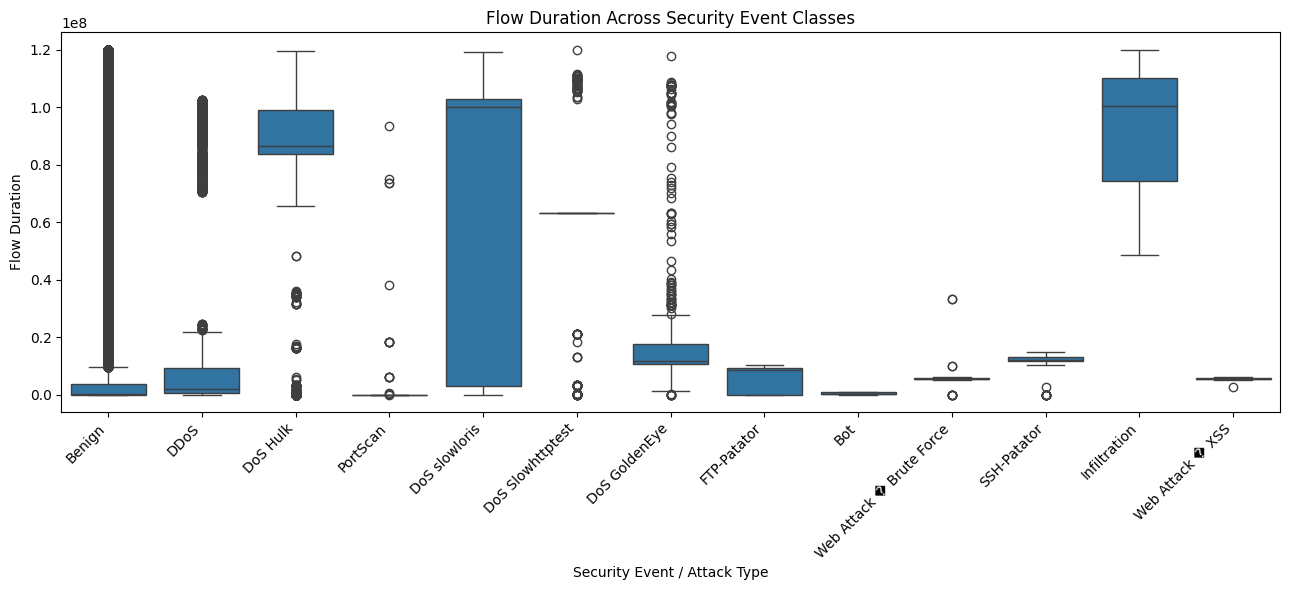

In [ ]:
# 22. Feature vs attack class
feature_for_class_plot = "Flow Duration"

plt.figure(figsize=(13, 6))
sns.boxplot(
    data=plot_sample,
    x="Label",
    y=feature_for_class_plot
)
plt.title(f"{feature_for_class_plot} Across Security Event Classes")
plt.xlabel("Security Event / Attack Type")
plt.ylabel(feature_for_class_plot)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 9. Correlation analysis

Correlation is calculated only on numeric features. Because there are 77 features, a full heatmap can be large; the notebook also provides a focused heatmap for representative features.


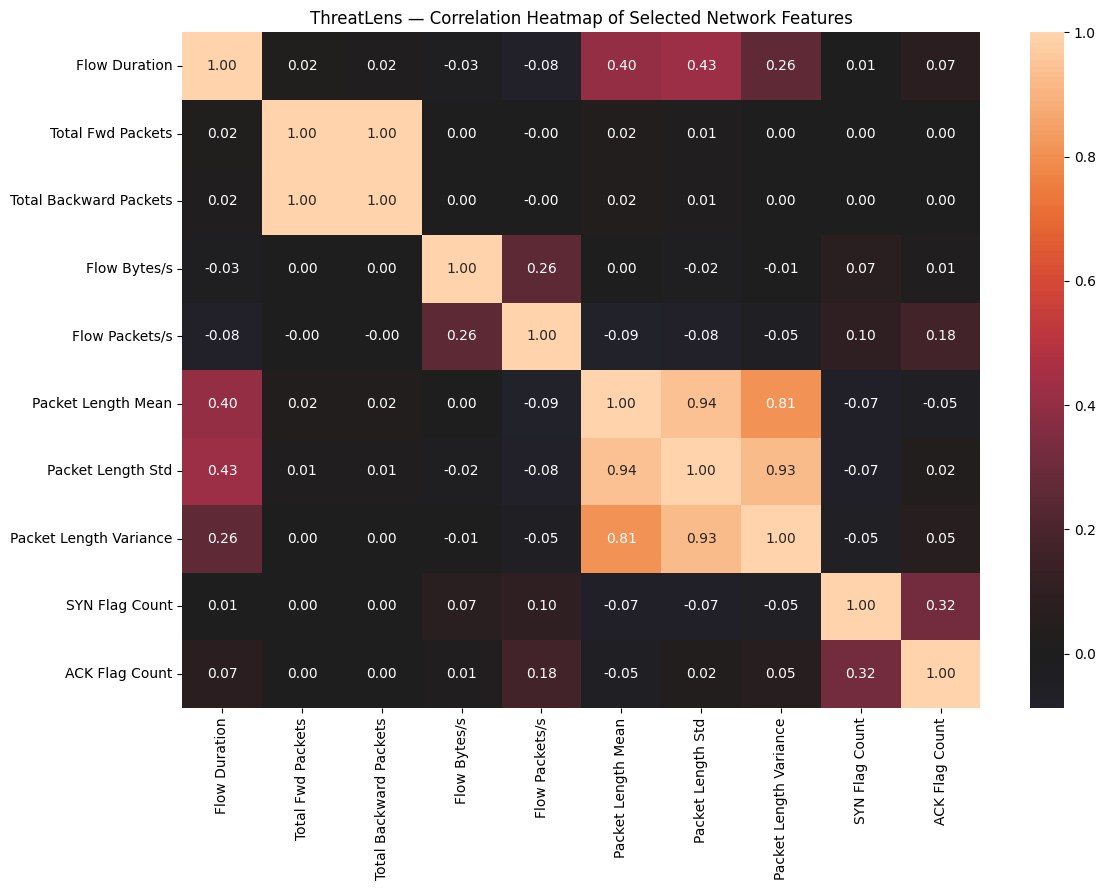

In [ ]:
# 23. Correlation matrix for representative features
corr_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Packet Length Mean",
    "Packet Length Std",
    "Packet Length Variance",
    "SYN Flag Count",
    "ACK Flag Count",
    "Average Packet Size"
]
corr_features = [c for c in corr_features if c in df.columns]

corr = df[corr_features].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", center=0)
plt.title("ThreatLens — Correlation Heatmap of Selected Network Features")
plt.tight_layout()
plt.show()


In [ ]:
# 24. Highest absolute correlations among selected features
corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .abs()
        .sort_values(ascending=False)
)

display(corr_pairs.head(15).to_frame("Absolute_Correlation"))


Absolute_Correlation
Total Fwd Packets  Total Backward Packets              0.999070
Packet Length Mean Packet Length Std                   0.942008
Packet Length Std  Packet Length Variance              0.925499
Packet Length Mean Packet Length Variance              0.806300
Flow Duration      Packet Length Std                   0.428514
                   Packet Length Mean                  0.398319
SYN Flag Count     ACK Flag Count                      0.318195
Flow Duration      Packet Length Variance              0.258270
Flow Bytes/s       Flow Packets/s                      0.255577
Flow Packets/s     ACK Flag Count                      0.176105
                   SYN Flag Count                      0.102168
                   Packet Length Mean                  0.086990
                   Packet Length Std                   0.078539
Flow Duration      Flow Packets/s                      0.077337
                   ACK Flag Count                      0.073880

## 10. Prepare the cleaned dataset

Two outputs are created:

**A. `ThreatLens_Cleaned.csv`**  
Preserves the original multi-class `Label` and is the main cleaned dataset for Task 4 and the rule/explanation pipeline.

**B. `ThreatLens_ML_Metadata.csv`**  
Contains feature-level metadata for later modeling.

Scaling is intentionally demonstrated separately after the train/test split to avoid data leakage.


In [ ]:
# 25. Save the main cleaned dataset
# Keep the original 78-column structure (77 features + original multi-class Label).
cleaned_main = df.drop(columns=["Threat_Binary"])

cleaned_path = "/content/ThreatLens_Cleaned.csv"
cleaned_main.to_csv(cleaned_path, index=False)

print("Saved:", cleaned_path)
print("Shape:", cleaned_main.shape)


Saved: /content/ThreatLens_Cleaned.csv
Shape: (2231806, 78)


In [ ]:
# 26. Create feature metadata
metadata_rows = []

for col in cleaned_main.columns:
    metadata_rows.append({
        "Feature": col,
        "Data_Type": str(cleaned_main[col].dtype),
        "Missing_Count": int(cleaned_main[col].isna().sum()),
        "Unique_Values": int(cleaned_main[col].nunique()),
        "Role": (
            "Original Target"
            if col == "Label"
            else "Binary Target"
            if False
            else "Input Feature"
        )
    })

metadata_df = pd.DataFrame(metadata_rows)
display(metadata_df.head(20))

metadata_path = "/content/ThreatLens_Feature_Metadata.csv"
metadata_df.to_csv(metadata_path, index=False)
print("Saved:", metadata_path)


,Feature,Data_Type,Missing_Count,Unique_Values,Role
0,Protocol,int8,0,3,Input Feature
1,Flow Duration,int32,0,1050898,Input Feature
2,Total Fwd Packets,int32,0,1432,Input Feature
3,Total Backward Packets,int32,0,1747,Input Feature
4,Fwd Packets Length Total,int32,0,17928,Input Feature
5,Bwd Packets Length Total,int32,0,64698,Input Feature
6,Fwd Packet Length Max,int16,0,5279,Input Feature
7,Fwd Packet Length Min,int16,0,384,Input Feature
8,Fwd Packet Length Mean,float32,0,85557,Input Feature
9,Fwd Packet Length Std,float32,0,241199,Input Feature


Saved: /content/ThreatLens_Feature_Metadata.csv


## 11. Scaling demonstration for future ML

For machine learning, numerical features should be standardized when the selected algorithm benefits from scaling.

**Important:** The scaler must be fitted only on the training set. Fitting it on the entire dataset before splitting would leak information from the test set.


In [ ]:
# 27. Train/test split and leakage-safe scaling
X = df.drop(columns=["Label", "Threat_Binary"])
y = df["Threat_Binary"]

# All remaining columns are expected to be numeric in this dataset.
non_numeric_X = X.select_dtypes(exclude=np.number).columns.tolist()
print("Non-numeric model columns:", non_numeric_X)

# Convert to numeric defensively
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Fill any conversion-created missing values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training features:", X_train.shape[1])
print("Attack ratio:", round(y.mean(), 4))


Non-numeric model columns: []
Training samples: 1785444
Testing samples: 446362
Training features: 77
Attack ratio: 0.1508


In [ ]:
# 28. Verify scaling
print("Training scaled mean (first 10 features):")
print(np.round(X_train_scaled.mean(axis=0)[:10], 4))

print("\nTraining scaled std (first 10 features):")
print(np.round(X_train_scaled.std(axis=0)[:10], 4))


Training scaled mean (first 10 features):
[-0. -0. -0.  0.  0. -0.  0. -0. -0.  0.]

Training scaled std (first 10 features):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 12. Final validation

Task 4 is complete when:
- the dataset is loaded and combined,
- feature types are understood,
- summary statistics are produced,
- missing/infinite values are handled,
- duplicates are removed,
- outliers are identified and treated carefully,
- visual patterns are documented,
- the cleaned dataset is saved,
- scaling is prepared without test-set leakage.


In [ ]:
# 29. Final Task 4 validation report
final_report = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns in main cleaned dataset",
        "Original Target Classes",
        "Missing Values",
        "Duplicate Rows",
        "Infinite Values",
        "Numerical Features",
        "Categorical Features"
    ],
    "Value": [
        len(cleaned_main),
        len(cleaned_main.columns),
        cleaned_main["Label"].nunique(),
        int(cleaned_main.isnull().sum().sum()),
        int(cleaned_main.duplicated().sum()),
        int(np.isinf(cleaned_main.select_dtypes(include=np.number)).sum().sum()),
        len(cleaned_main.select_dtypes(include=np.number).columns),
        len(cleaned_main.select_dtypes(exclude=np.number).columns)
    ]
})

display(final_report)


In [ ]:
# 30. Download outputs
from google.colab import files

files.download("/content/ThreatLens_Cleaned.csv")
files.download("/content/ThreatLens_Feature_Metadata.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Task 4 Conclusion

The CICIDS2017 security-flow dataset was successfully loaded, combined, explored and cleaned for ThreatLens. The analysis examined dataset structure, feature types, summary statistics, class distribution, missing and infinite values, duplicates, outliers, correlations and feature distributions. Invalid values were treated and duplicate rows were removed. Statistical outliers were identified but not blindly deleted because extreme network traffic may represent genuine attacks. The cleaned multi-class dataset was exported for subsequent ThreatLens machine-learning, deep-learning and explainability phases. A leakage-safe StandardScaler procedure was also prepared for future modeling.
